> **📌 Event snapshot — Winterbrain 2025 workshop, Talk 1** (Nadja R. Ging-Jehli, Brown University).
> This notebook is preserved as taught and is not maintained. For current material, start with
> [the HSSM tutorial](https://lnccbrown.github.io/HSSM/tutorials/main_tutorial/); for model comparison, see
> [How to compare and interpret models](https://lnccbrown.github.io/HSSM/how_to/compare_models/).

# HSSM Tutorial Winterbrain 2025 (event snapshot)
### Nadja R. Ging-Jehli
#### Brown University
#### LNCC Lab (Michael J. Frank)


This is a slightly simplified version of the original workshop tutorial which you can find [here](https://github.com/gingjehli/HSSM/blob/main/HSSMtutorial_Winterbrain_light3.ipynb).

### Load Modules

In [1]:
# Import modules
import arviz as az
import jax
import matplotlib as plt
import pytensor

import hssm

pytensor.config.floatX = "float32"
jax.config.update("jax_enable_x64", False)

plt.use("Agg")
%matplotlib inline
%config InlineBackend.figure_format='retina'

# hssm.set_floatX("float32")

## 1. Overview of Sequential Sampling Models

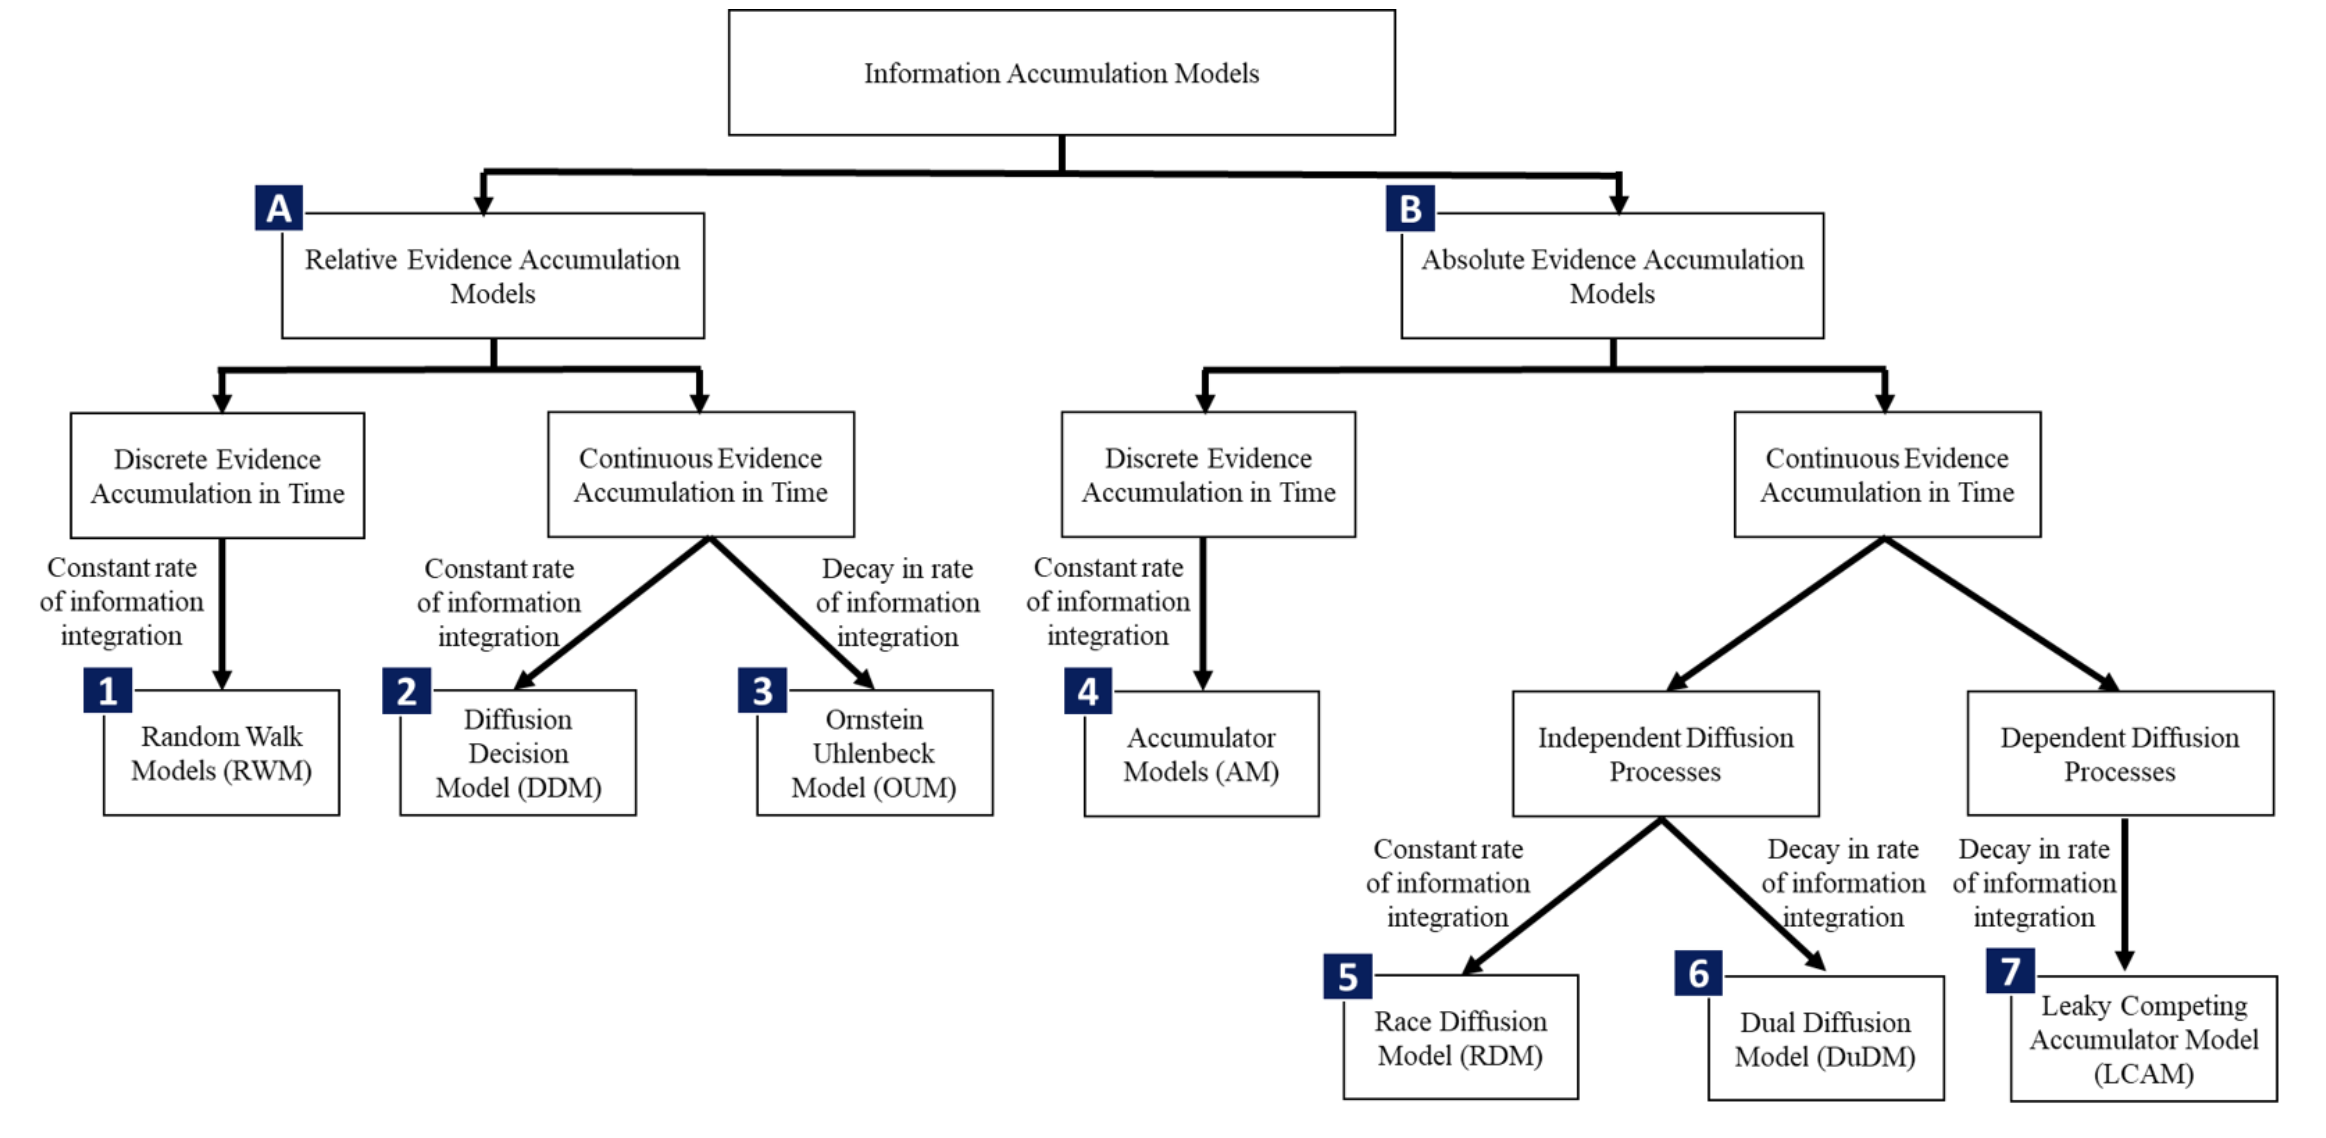

In [2]:
from IPython.display import Image

# Display the image
Image(filename="hssm_tutorial_workshop_1/ssm_overview.png")

### Some Useful Papers relevant for Neuroscience (a small selection)
- [Ratcliff, R., & Frank, M. J. (2012). Reinforcement-based decision making in corticostriatal circuits: mutual constraints by neurocomputational and diffusion models. Neural computation, 24(5), 1186-1229.](https://pubmed.ncbi.nlm.nih.gov/22295983/)
  
- [Turner, B. M., Palestro, J. J., Miletić, S., & Forstmann, B. U. (2019). Advances in techniques for imposing reciprocity in brain-behavior relations. Neuroscience & Biobehavioral Reviews, 102, 327-336.](https://pubmed.ncbi.nlm.nih.gov/31128445/)

- [Forstmann, B. U., Ratcliff, R., & Wagenmakers, E. J. (2016). Sequential sampling models in cognitive neuroscience: Advantages, applications, and extensions. Annual review of psychology, 67(1), 641-666.](https://pmc.ncbi.nlm.nih.gov/articles/PMC5112760/)

### Blogs (self-plug :))
https://www.gingjehli.com/research-blog

In [3]:
### Check supported models
hssm.defaults.SupportedModels

typing.Literal['ddm', 'ddm_sdv', 'full_ddm', 'angle', 'angle_extended', 'levy', 'ornstein', 'weibull', 'race_no_bias_angle_4', 'ddm_seq2_no_bias', 'gamma_drift', 'gamma_drift_angle', 'lba3', 'lba4', 'lba2', 'racing_diffusion_3', 'poisson_race', 'softmax_inv_temperature_2', 'softmax_inv_temperature_3']

In [4]:
### Details about a particular model
hssm.modelconfig.get_default_model_config("weibull")
##### the bounds within "likelihoods" provide reasonable parameter
##### values (take this with a grain of salt)

{'response': ['rt', 'response'],
 'list_params': ['v', 'a', 'z', 't', 'alpha', 'beta'],
 'choices': [-1, 1],
 'description': None,
 'likelihoods': {'approx_differentiable': {'loglik': 'weibull.onnx',
   'backend': 'jax',
   'default_priors': {},
   'bounds': {'v': (-2.5, 2.5),
    'a': (0.3, 2.5),
    'z': (0.2, 0.8),
    't': (0.001, 2.0),
    'alpha': (0.31, 4.99),
    'beta': (0.31, 6.99)},
   'extra_fields': None}}}

In [5]:
hssm.modelconfig.get_default_model_config("ddm")

{'response': ['rt', 'response'],
 'list_params': ['v', 'a', 'z', 't'],
 'choices': [-1, 1],
 'description': 'The Drift Diffusion Model (DDM)',
 'likelihoods': {'analytical': {'loglik': <function hssm.likelihoods.analytical.logp_ddm(data: numpy.ndarray, v: float, a: float, z: float, t: float, err: float = 1e-15, k_terms: int = 20, epsilon: float = 1e-15) -> numpy.ndarray>,
   'backend': None,
   'bounds': {'v': (-inf, inf),
    'a': (0.0, inf),
    'z': (0.0, 1.0),
    't': (0.0, inf)},
   'default_priors': {'t': {'name': 'HalfNormal', 'sigma': 2.0}},
   'extra_fields': None},
  'approx_differentiable': {'loglik': 'ddm.onnx',
   'backend': 'jax',
   'default_priors': {'t': {'name': 'HalfNormal', 'sigma': 2.0}},
   'bounds': {'v': (-3.0, 3.0),
    'a': (0.3, 2.5),
    'z': (0.0, 1.0),
    't': (0.0, 2.0)},
   'extra_fields': None},
  'blackbox': {'loglik': <function hssm.likelihoods.blackbox.hddm_to_hssm.<locals>.outer(data: numpy.ndarray, *args, **kwargs)>,
   'backend': None,
   'bound

#### Notes
- there is a difference between "ddm" and "full_ddm"
- the bounds within "likelihoods" provide reasonable param values (but take this with a grain of salt)
- the order of "list_params" is important

## 2. Regression-based modeling 

### Case Study 1: 1 hierarchical layer (trial-level) with 1 within-subject coefficient)
- you have intracranial recording in STN and want to understand the decision-relevant dynamics in the activity
- we assume that activity in STN varies on a trial-by-trial basis in a systematic way
- your Hypothesis: STN is implicated in response cautiousness
- you want to test this hypothesis using a classical DDM
#### Question to audience: which model parameter does STN modulate?

#### Step 1: Regression-based data simulation (one subjects)

In [6]:
import numpy as np
import pandas as pd
from ssms.basic_simulators.simulator import simulator

v_true = 0.5
a_true = 1.5
z_true = 0.5
t_true = 0.5
# a changes trial wise
# a_trialwise = np.random.normal(loc=2, scale=0.3, size=1000)
Intercept = 1.5
zSTN = np.random.normal(loc=1, scale=1, size=1000).astype(np.float32)
a_trialwise = Intercept + 0.5 * zSTN

# a changes trial wise
theta_mat = np.zeros((1000, 4))
theta_mat[:, 0] = v_true  # v
theta_mat[:, 1] = a_trialwise  # a
theta_mat[:, 2] = z_true  # z
theta_mat[:, 3] = t_true  # t

# simulate data
sim_out_trialwise = simulator(
    theta=theta_mat,  # parameter_matrix
    model="ddm",  # specify model (many are included in ssms)
    n_samples=1,  # number of samples for each set of parameters
    # (plays the role of `size` parameter in `hssm.simulate_data`)
)

# Turn into nice dataset
df_ddm_reg_case1 = pd.DataFrame(
    np.column_stack(
        [sim_out_trialwise["rts"][:, 0], sim_out_trialwise["choices"][:, 0]]
    ),
    columns=["rt", "response"],
)

df_ddm_reg_case1["zSTN"] = zSTN
df_ddm_reg_case1

,rt,response,zSTN
0,2.714748,1.0,0.572033
1,0.885337,1.0,-1.185438
2,2.428766,1.0,1.808630
3,3.603816,1.0,0.139819
4,0.998441,1.0,-0.741619
...,...,...,...
995,6.421622,1.0,0.882612
996,1.800721,1.0,0.991152
997,2.228743,1.0,-0.046159
998,7.574280,1.0,1.537807


#### Looking at the data, what do you notice?

#### Required Data Structure for HSSM
- we need variables labeled as "rt" and "response"
- make sure rt are in seconds
- responses are (1,-1) because you are in a classical DDM setting
- make sure regressors are z-scored (particularly important when you have more than two regressors)

#### Step 2: Model Setup & Priors

In [7]:
model_ddm_reg_case1 = hssm.HSSM(
    data=df_ddm_reg_case1,
    model="ddm",
    include=[
        {
            "name": "a",
            "formula": "a ~ 1 + zSTN",
            "prior": {
                # All ways to specify priors in the non-regression case
                # work the same way here.
                "Intercept": {"name": "Normal", "mu": 1.5, "sigma": 1.0},
                "zSTN": {"name": "Normal", "mu": 0, "sigma": 1.0},
            },
            "link": "identity",
        }
    ],
)

Model initialized successfully.


##### Notes to Step 2
- make sure your priors are reasonable (always double-check)
- see my blog for useful notes for defining priors on each of these params 
https://www.gingjehli.com/single-post/choosing-effective-samplers-and-setting-priors
- priors are particularly important in these more complex regression-based models
-  it can also be helpful to set "init_val" for the sampler so it starts in a reasonable region. 

#### Step 3: Double-check model specification

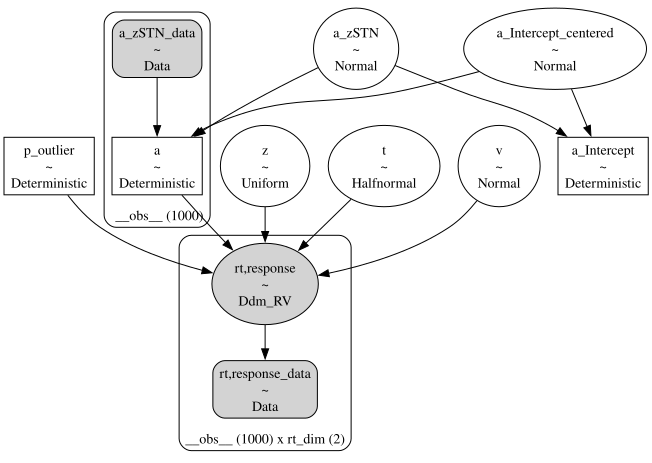

In [8]:
# graphical illustration of model
model_ddm_reg_case1.graph()

#### Step 4: Sampling from the Posterior Distribution

In [9]:
# suppress warnings
import warnings

warnings.filterwarnings("ignore")
samples_model_ddm_reg_case1 = model_ddm_reg_case1.sample(
    sampler="numpyro",
    cores=2,
    chains=2,
    draws=500,
    tune=500,
    idata_kwargs=dict(log_likelihood=True),
)

Using default initvals. 



NUTS[numpyro]: [z, v, t, a_zSTN, a_Intercept_centered]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:00<00:10, 91.15it/s, 31 steps of size 1.21e-02. acc. prob=0.74]

warmup:  10%|█         | 100/1000 [00:00<00:05, 171.35it/s, 15 steps of size 1.57e-02. acc. prob=0.76]

...

sample:  85%|████████▌ | 852/1000 [00:02<00:00, 428.80it/s, 15 steps of size 4.20e-01. acc. prob=0.90]

sample:  90%|█████████ | 902/1000 [00:02<00:00, 437.41it/s, 7 steps of size 4.20e-01. acc. prob=0.90] 

sample:  95%|█████████▌| 952/1000 [00:02<00:00, 442.04it/s, 15 steps of size 4.20e-01. acc. prob=0.90]

sample: 100%|██████████| 1000/1000 [00:02<00:00, 396.89it/s, 3 steps of size 4.20e-01. acc. prob=0.91]

We recommend running at least 4 chains for robust computation of convergence diagnostics


##### Notes to Step 4
- in a real analysis, you would want to run more chains (usually >=4)
- if models don't converge, as a first step, it is typically a good idea to increase the chain length
- depending on task structure, some model params are more/less likely to trade-off (e.g., simple task design, `t` & `a` are often anti-correlated)
- if there are parameter trade-offs or depending on your regression equation, it can be helpful to play around with the sampler
- though: numpyro sampler does not work with blackbox likelihoods.
- sometime variational inference (VI) can be a helpful alternative to MCMC (check out the dedicated tutorials in the HSSM documentation)

#### Step 5: Model Validation

##### What do you think about these results below (also given Jensen's part)?

In [10]:
#### quick check on posterior statistics
az.summary(model_ddm_reg_case1.traces)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
z,0.4924,0.0123,0.47,0.51,614,756,1.00,0.0005,0.00035
a_Intercept_centered,1.931,0.036,1.9,2,629,649,1.01,0.0014,0.0013
a_Intercept,1.415,0.033,1.4,1.5,800,721,1.01,0.0012,0.0011
v,0.552,0.026,0.51,0.59,777,742,1.00,0.00094,0.00073
a_zSTN,0.526,0.025,0.49,0.57,823,653,1.00,0.00086,0.0008
t,0.538,0.023,0.5,0.57,706,646,1.00,0.00088,0.00085


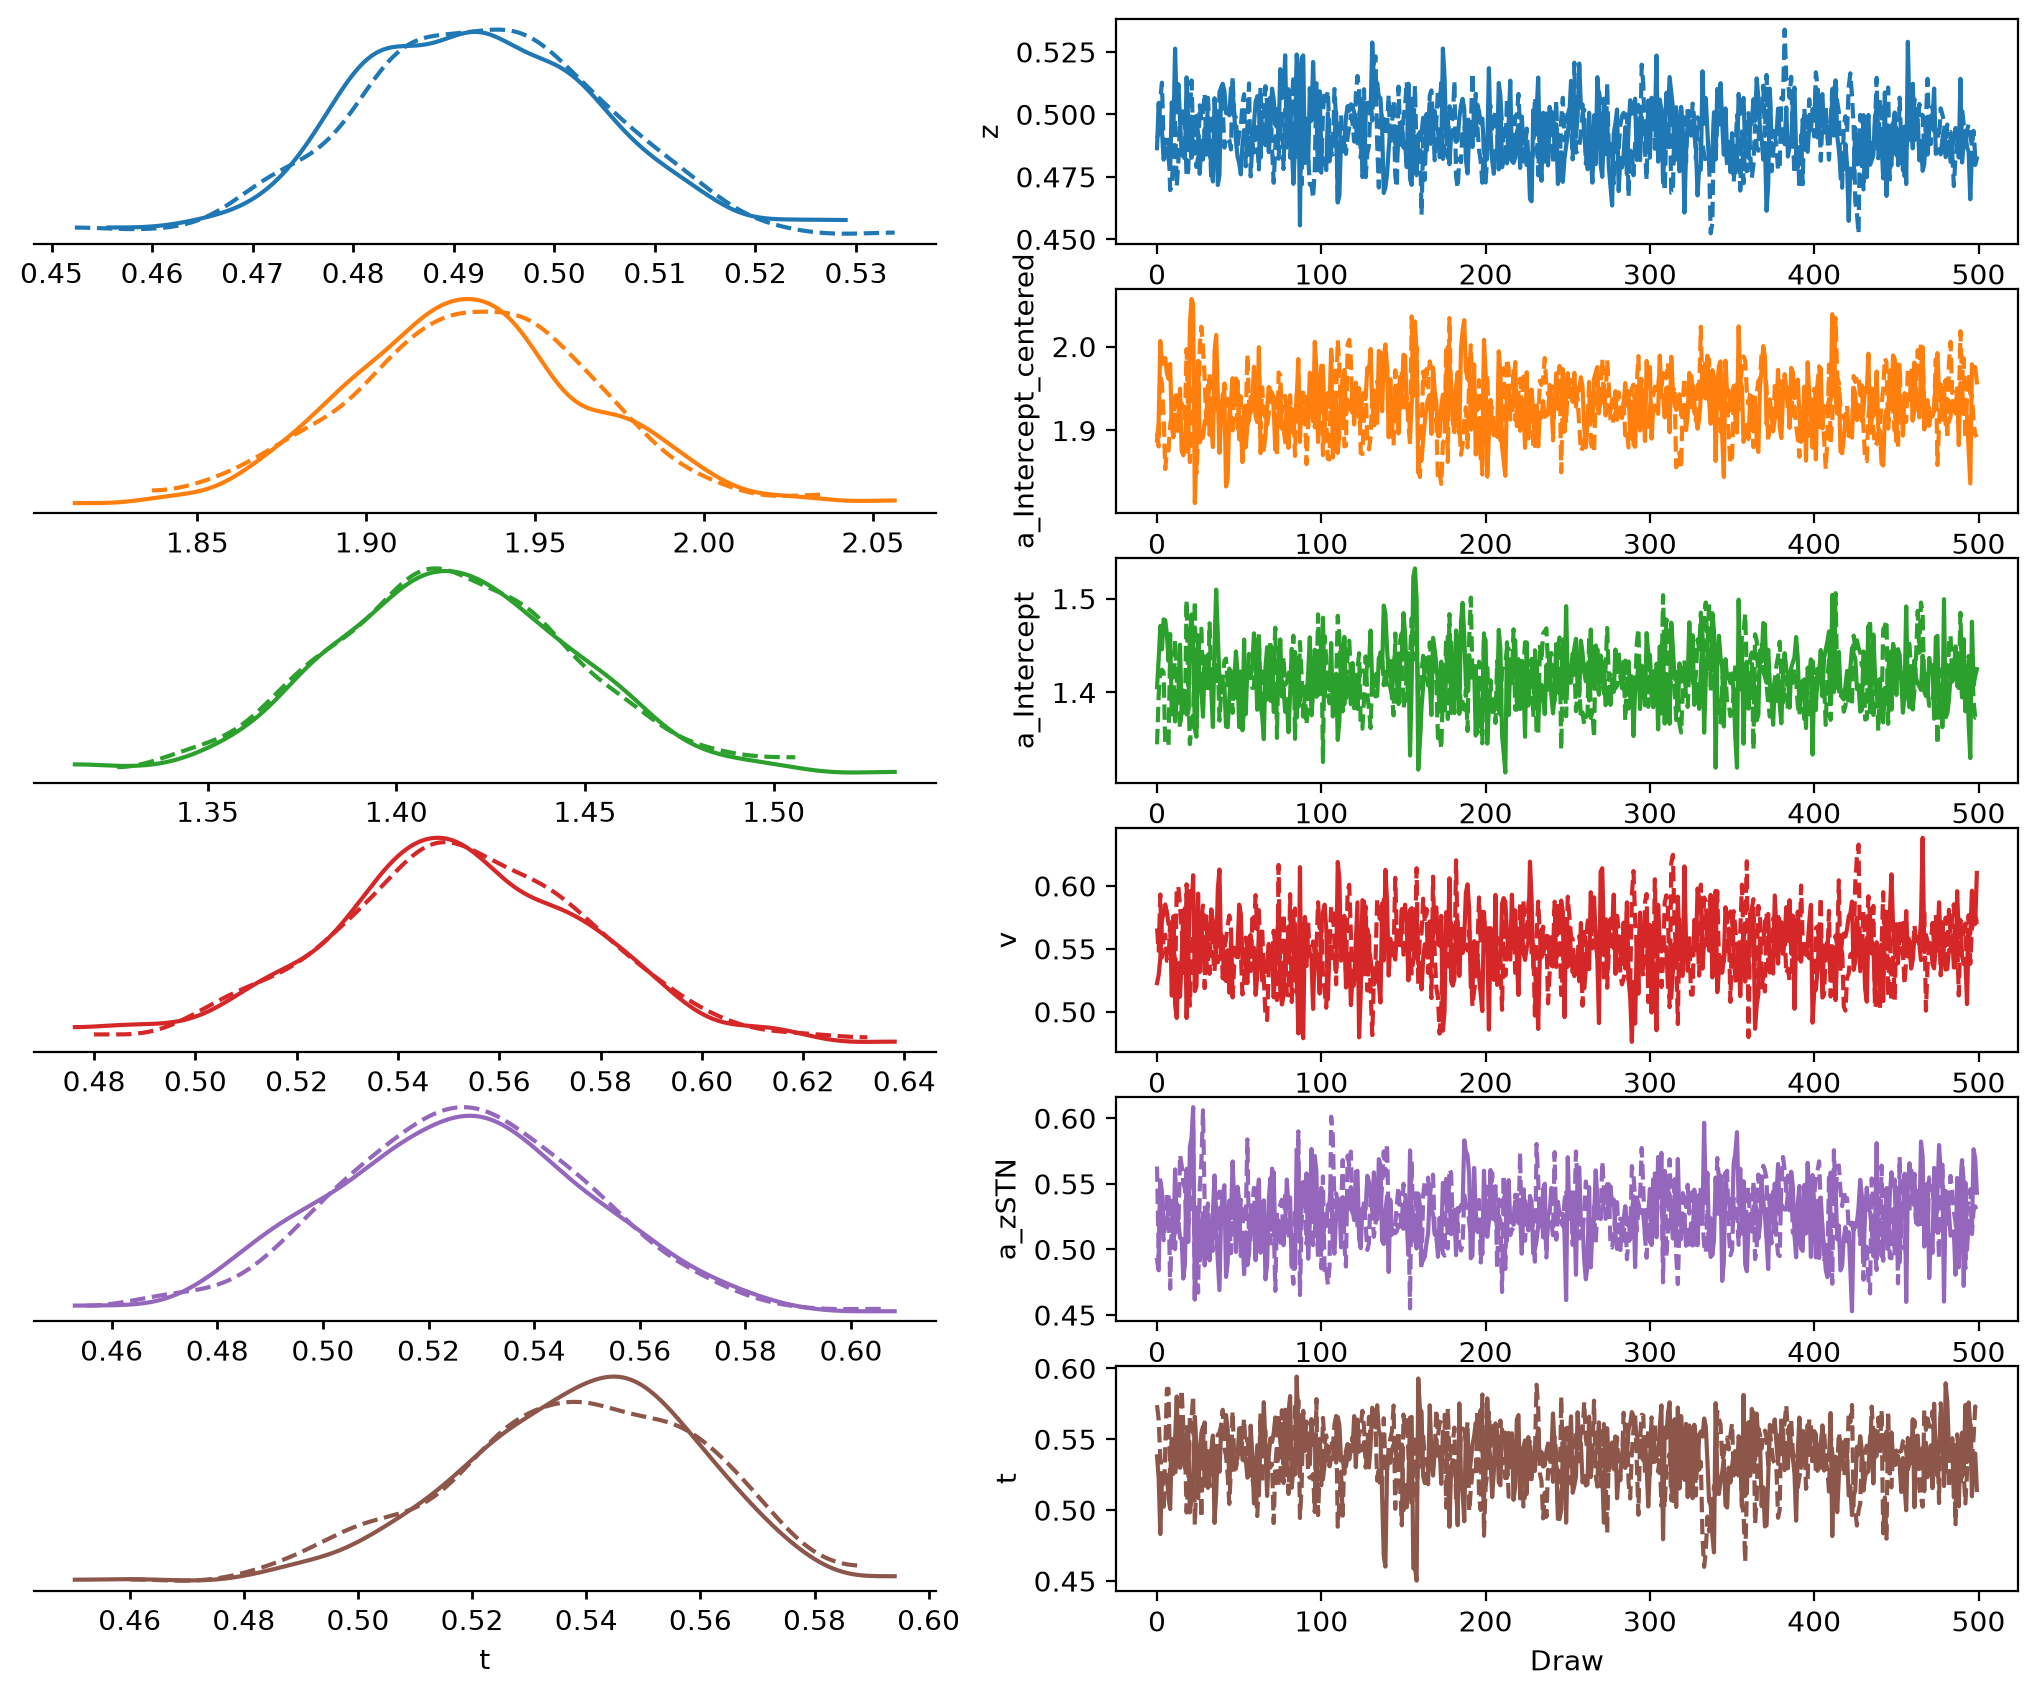

In [11]:
#### trace plots
az.plot_trace_dist(model_ddm_reg_case1.traces)

### Case Study 2: Participant hierarchy on two within-subject coefficients

- besides from STN, we also have an indirect nogo pathway via GPe
- this time, we want to assume that activity in these components modulates drift rate
- even though there is evidence that STN modulates the boundary, we always want to check different model specifications

#### Step 1: Regression-based data simulation (multiple subjects)

In [12]:
# Function to simulate data for one participant
def simulate_participant(participant_id, size=300):
    """Simulate DDM trial data for one participant."""
    intercept = 1.5
    zSTN = np.random.normal(loc=1, scale=2, size=size)
    zGPe = np.random.normal(loc=1, scale=2, size=size)
    v = intercept + 0.8 * zSTN + 0.3 * zGPe

    # Assume `hssm.simulate_data` returns a DataFrame
    true_values = np.column_stack(
        [v, np.repeat([[1.5, 0.5, 0.5]], axis=0, repeats=300)]
    )

    dataset_reg_v = hssm.simulate_data(
        model="ddm",
        theta=true_values,
        size=1,  # Generate one data point for each of the 1000 set of true values
    )

    # Adding additional variables to the dataset
    dataset_reg_v["zSTN"] = zSTN
    dataset_reg_v["zGPe"] = zGPe
    dataset_reg_v["participant_id"] = str(participant_id)
    return dataset_reg_v


# Simulate data for 10 participants

# Combine datasets into one DataFrame
combined_dataset = pd.concat(
    [simulate_participant(i, size=300) for i in range(1, 11)], ignore_index=True
)
combined_dataset

,rt,response,zSTN,zGPe,participant_id
0,2.065519,1.0,-0.856332,0.278384,1
1,0.779758,1.0,-0.569553,1.534565,1
2,1.503307,1.0,-0.796662,1.695797,1
3,1.571034,1.0,2.407502,-2.407162,1
4,1.509790,1.0,0.926585,1.867392,1
...,...,...,...,...,...
2995,1.282206,1.0,2.239723,-1.139708,10
2996,1.839572,-1.0,-4.615836,3.444517,10
2997,0.814476,1.0,2.813237,2.494100,10
2998,5.656347,-1.0,-2.239449,1.118870,10


#### Step 2: Model Setup & Priors

##### Alternative 1: A centered model
- specification where the subject-specific coefficients are coming from one hierarchical prior (mother distribution with mu and sigma)
- we can also call it as "0+" models
- this is the specification used in HDDM
- in this case, it's important to set "noncentered=False" (by default it's set to "True")
- The group distributions here will be recovered as v_1|subject_mu and v_x|subject_mu

In [13]:
model_reg_v_ex2_A1 = hssm.HSSM(
    data=combined_dataset,
    model="ddm",
    include=[
        {
            "name": "v",
            "formula": "v ~ 0 + (1 + zSTN + zGPe | participant_id)",
            "prior": {
                "1|participant_id": {
                    "name": "Normal",
                    "mu": {"name": "Normal", "mu": 1, "sigma": 1.0, "initval": 0},
                    "sigma": {"name": "HalfNormal", "sigma": 1, "initval": 0.25},
                },
                "zSTN|participant_id": {
                    "name": "Normal",
                    "mu": {"name": "Normal", "mu": 0, "sigma": 1.0, "initval": 0},
                    "sigma": {"name": "HalfNormal", "sigma": 1, "initval": 0.25},
                },
                "zGPe|participant_id": {
                    "name": "Normal",
                    "mu": {"name": "Normal", "mu": 0, "sigma": 1.0, "initval": 0},
                    "sigma": {"name": "HalfNormal", "sigma": 1, "initval": 0.25},
                },
            },
            "link": "identity",
        }
    ],
    noncentered=False,
    p_outlier=0.05,
)

Model initialized successfully.


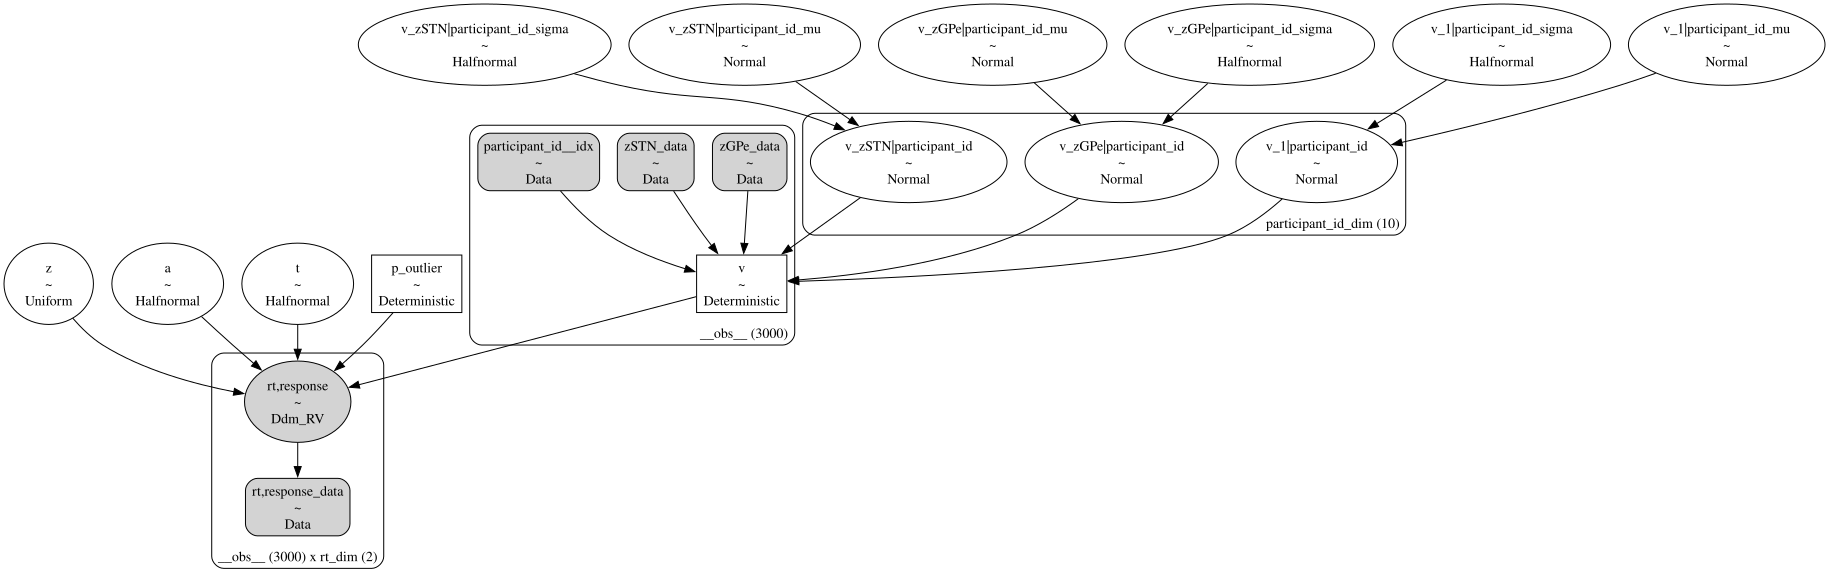

In [14]:
# graphical illustration of model
model_reg_v_ex2_A1.graph()

##### Alternative 2: A non-centered model
- Non-centered means that each subject is estimated as offset from the group mean
- in this case the group means will be zSTN and zGPe.
- The priors are different here because now we want the mu for the random subject effects to be 0
- the mu should not be estimated from a hyperprior simultaneously with the fixed effects, as those will tradeoff and could produce convergence issues  - we still estimate the sigmas with a hyperprior to allow us to get indiv params
- now we keep noncentered=true.

In [15]:
model_reg_v_ex2_A2 = hssm.HSSM(
    data=combined_dataset,
    include=[
        {
            "name": "v",
            "formula": "v ~ 1 + zSTN + zGPe + (1 + zSTN + zGPe | participant_id)",
            "prior": {
                # All ways to specify priors in the non-regression case
                # work the same way here.
                "Intercept": {"name": "Normal", "mu": 1.0, "sigma": 1.0},
                "zSTN": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "1|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1.0},
                },
                "zSTN|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1.0},
                },
                "zGPe|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1.0},
                },
            },
            "link": "identity",
        }
    ],
    noncentered=True,
    p_outlier=0.05,
)

Model initialized successfully.


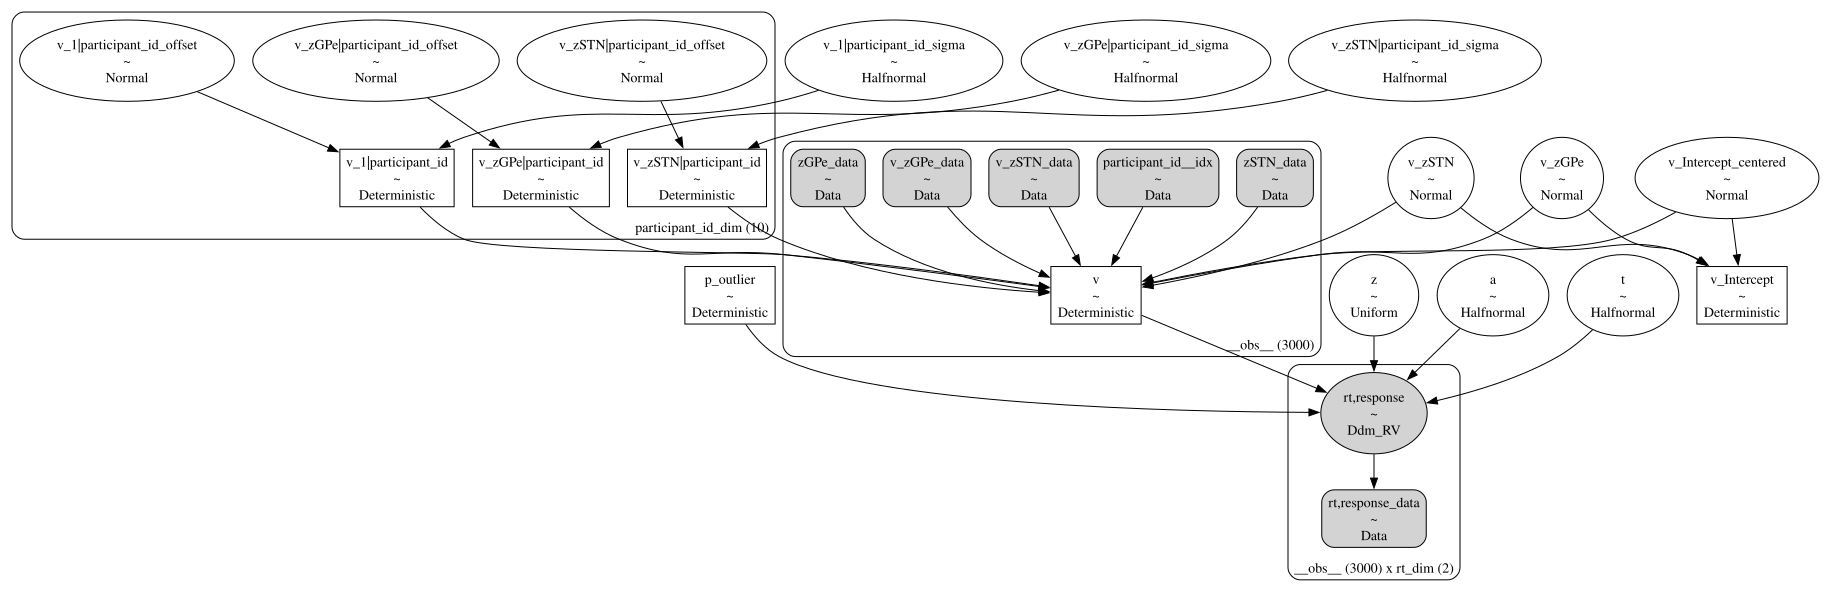

In [16]:
model_reg_v_ex2_A2.graph()

### Important note
Note that in this non-centered model, you will need to specify each individual coefficient's prior (at least for your regression equation). See example below

#### Step 4: Sampling from the Posterior Distribution (Bayesian Model Fitting based on MCMC Procedure)

In [17]:
## centered model version
samples_model_reg_v_ex2_A1 = model_reg_v_ex2_A1.sample(
    sampler="numpyro",
    cores=3,
    chains=3,
    draws=500,
    tune=500,
    idata_kwargs=dict(log_likelihood=True),
)

Using default initvals. 



NUTS[numpyro]: [a, z, t, v_1|participant_id_mu, v_1|participant_id_sigma, v_1|participant_id, v_zSTN|participant_id_mu, v_zSTN|participant_id_sigma, v_zSTN|participant_id, v_zGPe|participant_id_mu, v_zGPe|participant_id_sigma, v_zGPe|participant_id]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:02<00:55, 17.14it/s, 31 steps of size 5.31e-03. acc. prob=0.74]

warmup:  10%|█         | 100/1000 [00:05<00:47, 18.94it/s, 63 steps of size 6.91e-03. acc. prob=0.76]

...

sample: 100%|██████████| 1000/1000 [01:13<00:00, 13.55it/s, 63 steps of size 9.98e-02. acc. prob=0.86]

There were 68 divergences after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [18]:
## centered model version
samples_model_reg_v_ex2_A2 = model_reg_v_ex2_A2.sample(
    sampler="numpyro",
    cores=3,
    chains=3,
    draws=500,
    tune=500,
    idata_kwargs=dict(log_likelihood=True),
)

Using default initvals. 



NUTS[numpyro]: [a, z, t, v_zSTN, v_zGPe, v_Intercept_centered, v_1|participant_id_sigma, v_1|participant_id_offset, v_zSTN|participant_id_sigma, v_zSTN|participant_id_offset, v_zGPe|participant_id_sigma, v_zGPe|participant_id_offset]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   0%|          | 0/1000 [00:10<?, ?it/s, 511 steps of size 6.20e-03. acc. prob=0.73]

warmup:   5%|▍         | 47/1000 [00:11<03:44,  4.25it/s, 511 steps of size 4.23e-03. acc. prob=0.73]

...

sample:  99%|█████████▉| 994/1000 [00:56<00:00, 49.23it/s, 31 steps of size 1.61e-01. acc. prob=0.93]

sample: 100%|█████████▉| 999/1000 [00:56<00:00, 48.99it/s, 31 steps of size 1.61e-01. acc. prob=0.93]

sample: 100%|██████████| 1000/1000 [00:56<00:00, 17.60it/s, 31 steps of size 1.61e-01. acc. prob=0.93]

We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


#### Final notes:
- whether centered is better depends on the structure of your dataset
- the two models are mathematically equivalent, however the posterior geometry is affected by the parameterization
- in practice, you can try both and see which one works better
- [here](https://betanalpha.github.io/assets/case_studies/hierarchical_modeling.html) is a great (albeit non-trivial to digest) long blog post which touches on the topic in some detail`

#### Step 5: Model Validation

In [19]:
#### posterior statistics of centered model
az.summary(samples_model_reg_v_ex2_A2, var_names=["~_id"], filter_vars="like")

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
z,0.496,0.0109,0.48,0.51,2436,1163,1.00,0.00022,0.0003
t,0.5017,0.0059,0.49,0.51,2317,1264,1.00,0.00012,0.00016
v_Intercept,1.545,0.044,1.5,1.6,1340,1147,1.00,0.0012,0.0012
v_zGPe,0.2951,0.015,0.27,0.32,1532,1012,1.00,0.0004,0.00054
v_zSTN,0.8074,0.0185,0.78,0.84,1627,1142,1.00,0.00046,0.0005
v_Intercept_centered,2.597,0.054,2.5,2.7,1169,1176,1.00,0.0016,0.0016
a,1.518,0.027,1.5,1.6,2637,1133,1.00,0.00054,0.0008


No posterior_predictive samples found. Generating posterior_predictive samples using the provided DataTree object and the original data. This will modify the provided DataTree object, or if not provided, the traces object stored inside the model.


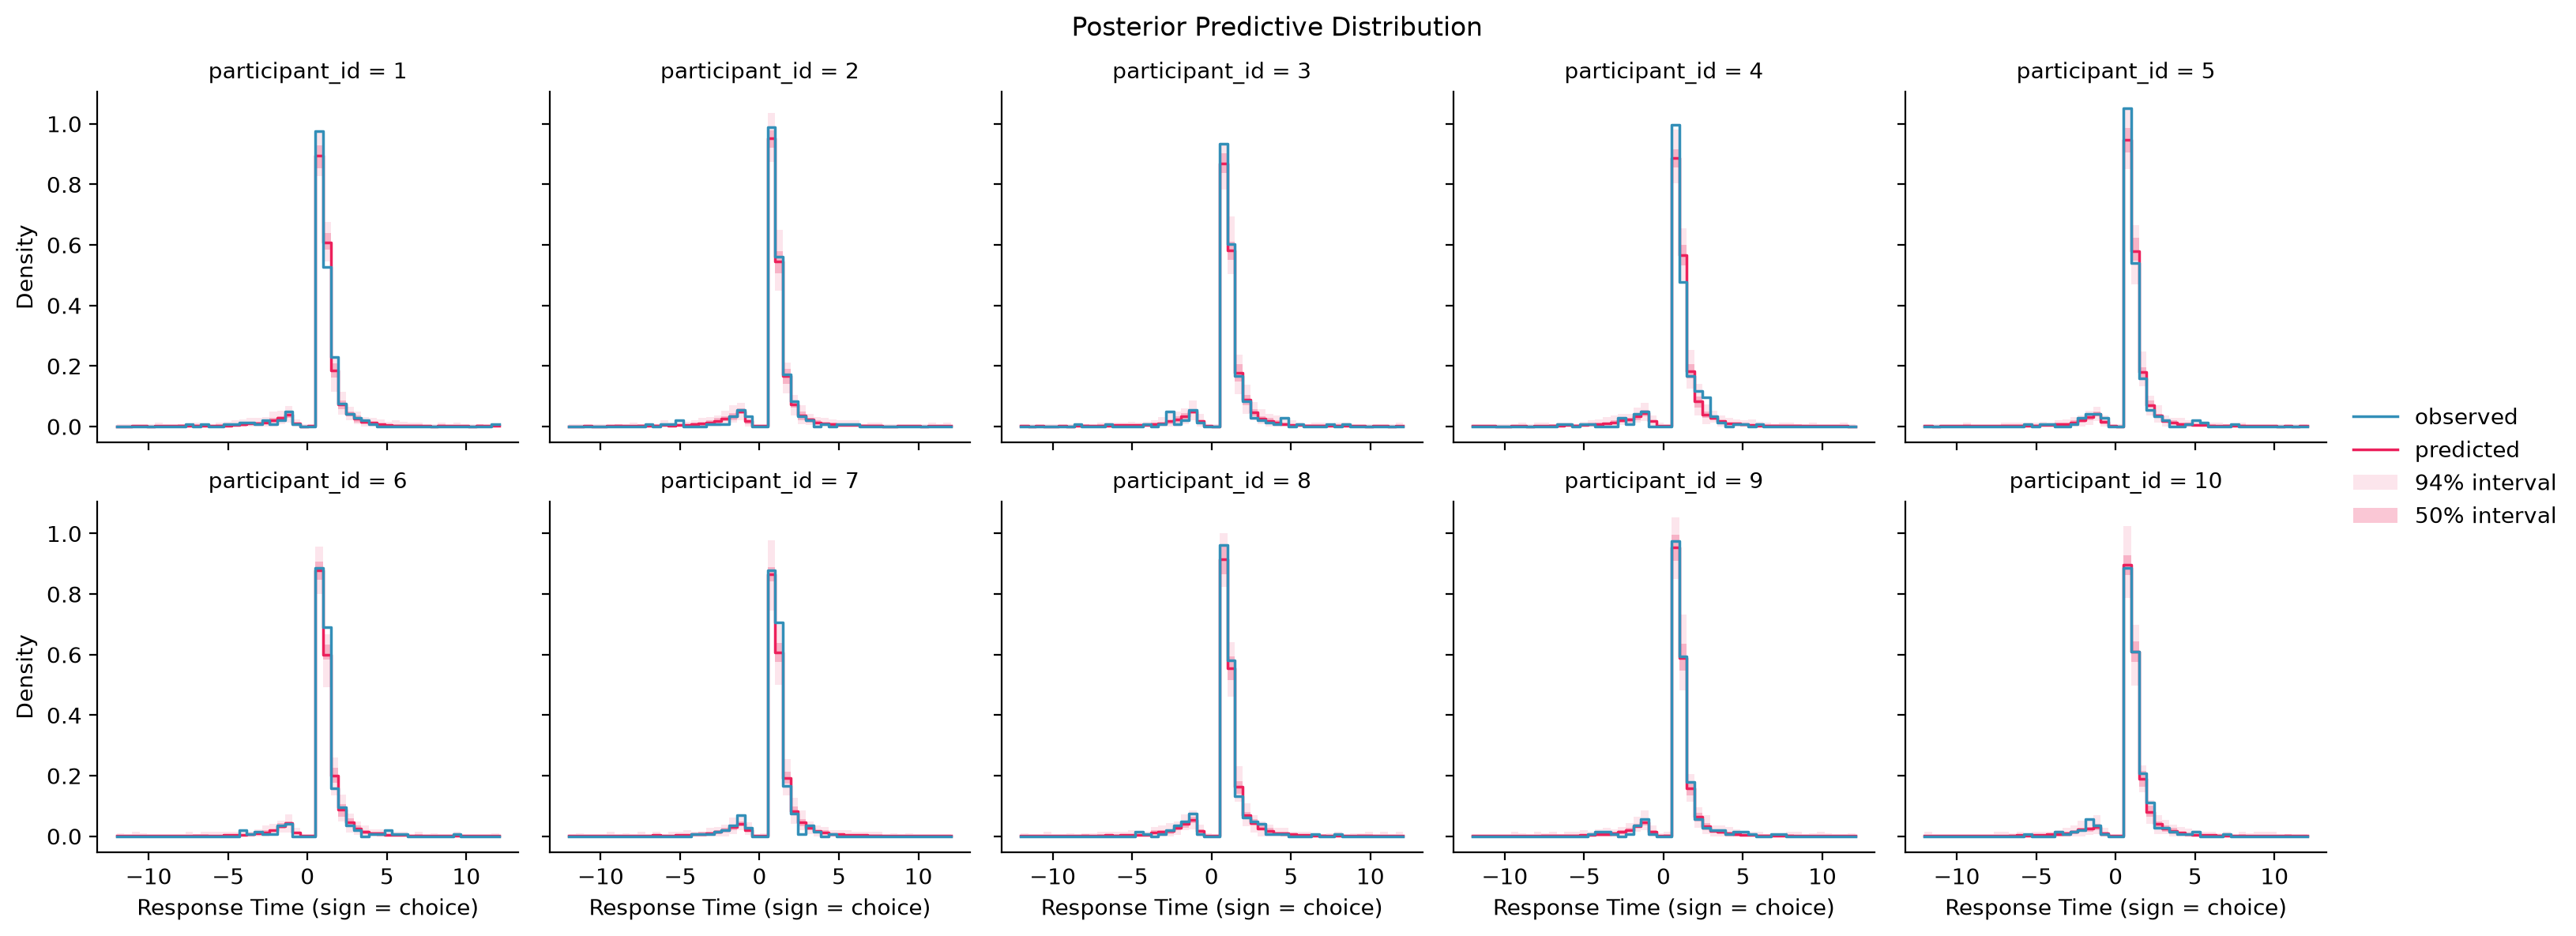

In [20]:
# Plotting the posterior predictive
hssm.plotting.plot_predictive(model_reg_v_ex2_A1, col="participant_id", col_wrap=5)

In [21]:
#### posterior statistics of non-centered model
az.summary(samples_model_reg_v_ex2_A2, var_names=["~_offset"], filter_vars="like")

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
z,0.496,0.0109,0.48,0.51,2436,1163,1.00,0.00022,0.0003
v_zSTN|participant_id_sigma,0.029,0.019,0.0043,0.062,473,643,1.00,0.00081,0.00055
t,0.5017,0.0059,0.49,0.51,2317,1264,1.00,0.00012,0.00016
v_1|participant_id_sigma,0.055,0.035,0.0075,0.12,553,698,1.01,0.0014,0.00097
v_Intercept,1.545,0.044,1.5,1.6,1340,1147,1.00,0.0012,0.0012
v_zGPe,0.2951,0.015,0.27,0.32,1532,1012,1.00,0.0004,0.00054
v_zSTN,0.8074,0.0185,0.78,0.84,1627,1142,1.00,0.00046,0.0005
v_Intercept_centered,2.597,0.054,2.5,2.7,1169,1176,1.00,0.0016,0.0016
a,1.518,0.027,1.5,1.6,2637,1133,1.00,0.00054,0.0008
v_zGPe|participant_id[1],-0.008,0.02,-0.043,0.02,1890,1216,1.00,0.0005,0.00073


No posterior_predictive samples found. Generating posterior_predictive samples using the provided DataTree object and the original data. This will modify the provided DataTree object, or if not provided, the traces object stored inside the model.


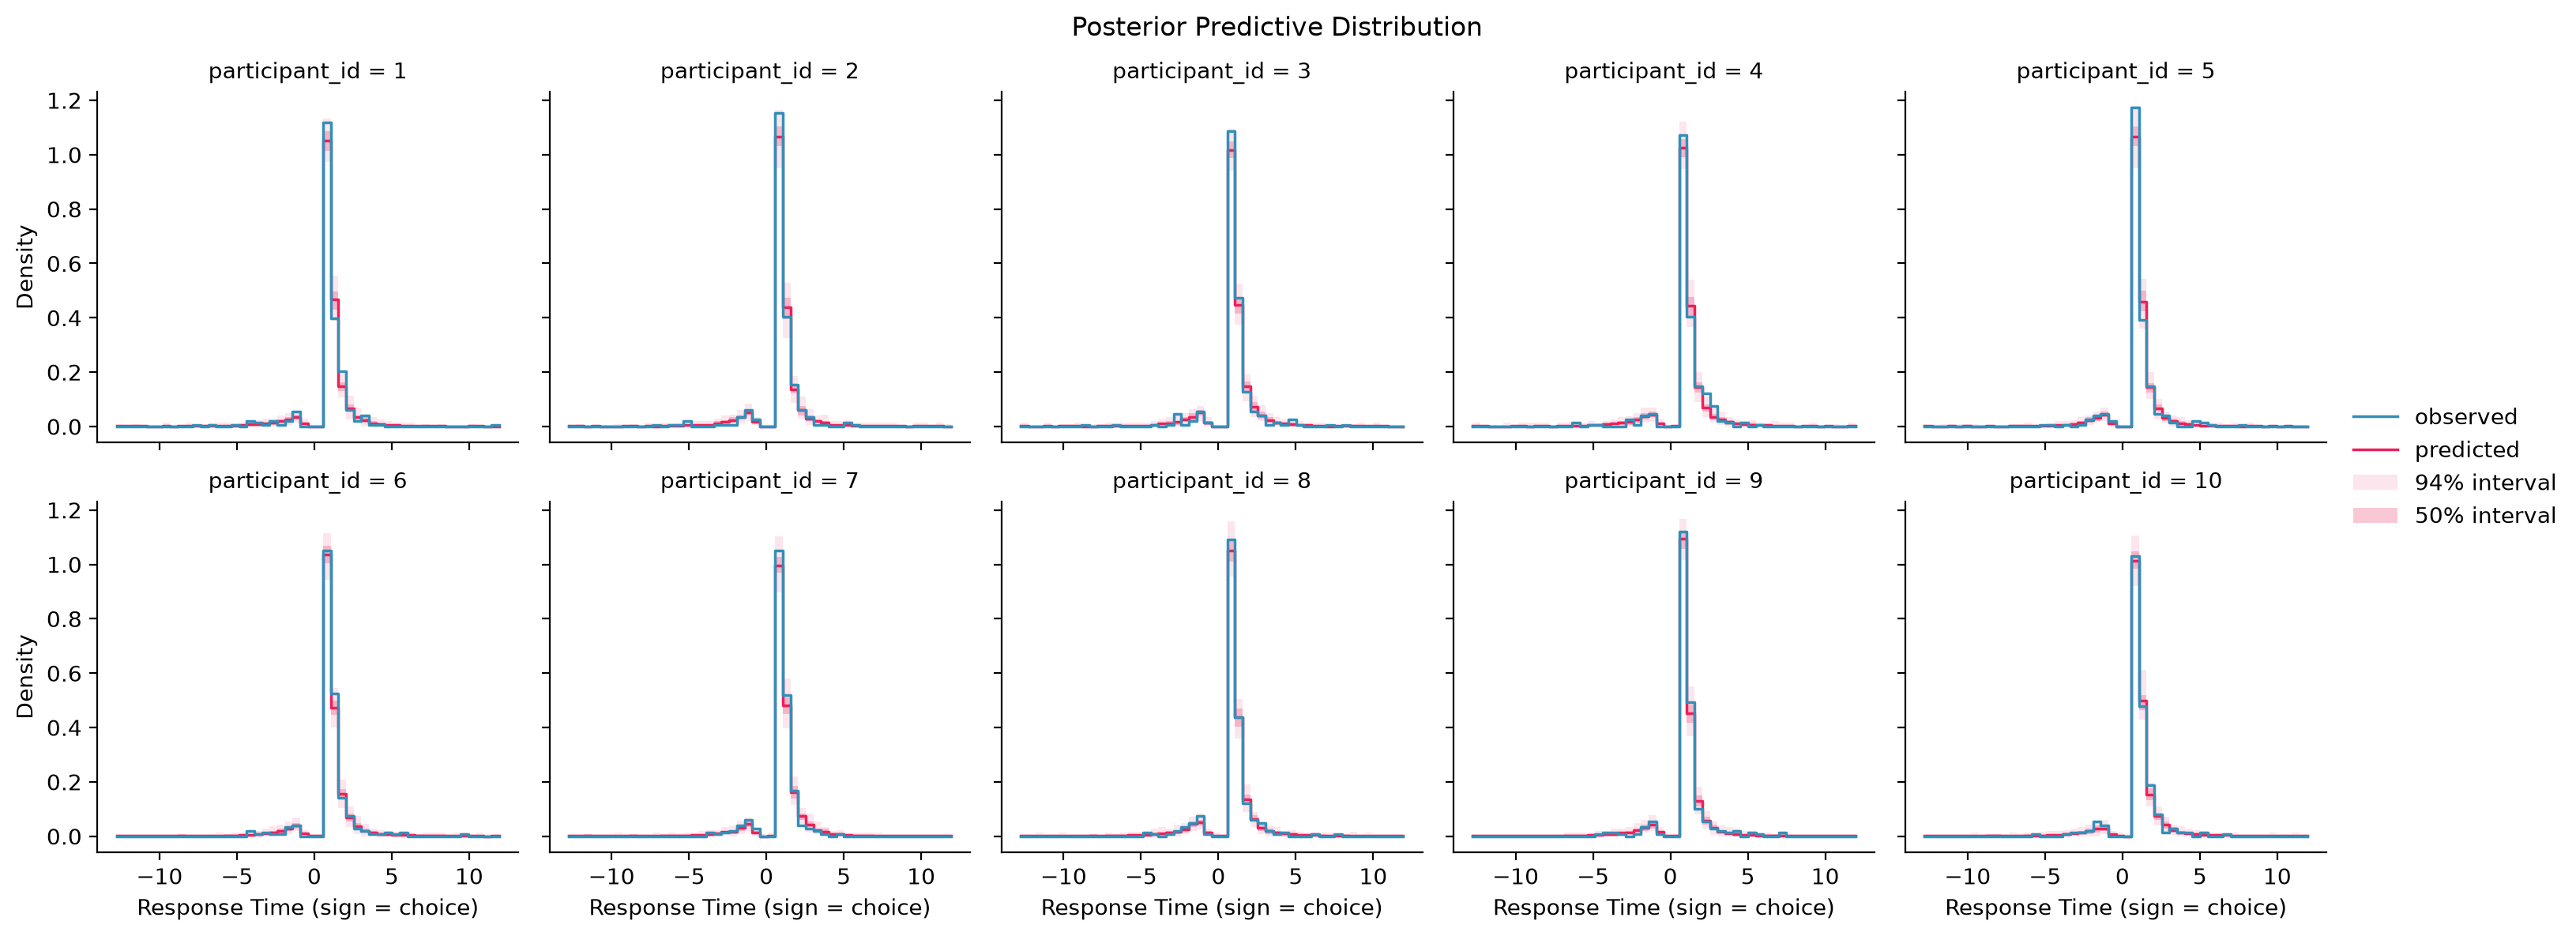

In [22]:
# Plotting the posterior predictive
hssm.plotting.plot_predictive(model_reg_v_ex2_A2, col="participant_id", col_wrap=5)

# Additional Case studies (between-subject & group variables)

### Case Study 3: Participant-level hierarchy,  two within-subject coefficients and one between-subject coefficient

- we still have the intracranial recordings
- but now you have different patients and they vary in symptom severity for Parkinson
- you wonder whether those with higher symptom severity have a lower drift rate because the modulation from STN is less efficient

#### Step 1: Regression-based data simulation (multiple subjects)

In [23]:
# Function to simulate data for one participant
def simulate_participant2(participant_id, sevScore, size=300):
    """Simulate DDM trial data for one participant with severity-dependent drift."""
    intercept = 0.5
    zSTN = np.random.normal(loc=1, scale=2, size=size)
    zGPe = np.random.normal(loc=1, scale=2, size=size)

    ## Strength of neural modulation depends on PD severity score

    #### Case 1: only the interaction btw sevScore & STN/GPe will turn out
    #### sign, the main effects of STN & GPe will disappear
    # v = intercept + 0.8 * zSTN * sevScore + 0.3 * zGPe * sevScore

    #### Case 2: main effects of STN/GPe will remain, plus a significant
    #### interaction, but no modulation on intercept
    if sevScore < 0.2:
        v = intercept + 0.8 * zSTN + 0.3 * zGPe
    elif sevScore >= 0.2 and sevScore < 0.4:
        v = intercept + 0.7 * zSTN + 0.25 * zGPe
    elif sevScore >= 0.4 and sevScore < 0.6:
        v = intercept + 0.6 * zSTN + 0.2 * zGPe
    elif sevScore >= 0.6 and sevScore < 0.8:
        v = intercept + 0.5 * zSTN + 0.15 * zGPe
    else:
        v = intercept + 0.4 * zSTN + 0.1 * zGPe

    # Assume `hssm.simulate_data` returns a DataFrame
    true_values = np.column_stack(
        [v, np.repeat([[1.5, 0.5, 0.5]], axis=0, repeats=size)]
    )
    dataset_reg_v = hssm.simulate_data(
        model="ddm",
        theta=true_values,
        size=1,  # Generate one data point for each of the 1000 set of true values
    )

    # Adding additional variables to the dataset
    dataset_reg_v["zSTN"] = zSTN
    dataset_reg_v["zGPe"] = zGPe
    dataset_reg_v["participant_id"] = str(participant_id)
    dataset_reg_v["sevScore"] = sevScore
    return dataset_reg_v


# Simulate data for four participants
### note that we assume that STN & GPe

# patients with severity scores
subj_list = [1, 1, 2, 3, 4, 5, 6, 7, 8, 8, 8]
sevscore_list = [0.00, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]

# Combine datasets into one DataFrame
combined_dataset2 = pd.concat(
    [
        simulate_participant2(subj, sevscore)
        for subj, sevscore in zip(subj_list, sevscore_list)
    ],
    ignore_index=True,
)
combined_dataset2

,rt,response,zSTN,zGPe,participant_id,sevScore
0,0.997766,1.0,0.792937,1.026383,1,0.0
1,1.475226,1.0,2.009290,2.677946,1,0.0
2,6.029260,-1.0,-1.064756,1.023052,1,0.0
3,0.986753,1.0,1.578136,-2.152491,1,0.0
4,0.952706,-1.0,-0.392209,-3.124231,1,0.0
...,...,...,...,...,...,...
3295,3.309756,1.0,0.663552,3.214937,8,1.0
3296,1.794291,1.0,-0.615654,3.042443,8,1.0
3297,3.950179,1.0,-2.142664,0.145767,8,1.0
3298,3.170299,1.0,-0.112101,-0.645987,8,1.0


#### Step 2: Model Setup & Priors

In [24]:
model_reg_v_ex3_A1 = hssm.HSSM(
    data=combined_dataset2,
    include=[
        {
            "name": "v",
            "formula": (
                "v ~ 1 + (zSTN + zGPe)*sevScore + (1 + zSTN + zGPe | participant_id)"
            ),
            "prior": {
                # All ways to specify priors in the non-regression case
                # work the same way here.
                "Intercept": {"name": "Normal", "mu": 1.5, "sigma": 1.0},
                "zSTN": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zSTN:sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe:sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "1|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1.0},
                },
                "zSTN|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1.0},
                },
                "zGPe|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1.0},
                },
            },
            "link": "identity",
        }
    ],
    noncentered=True,
    p_outlier=0.05,
)

Model initialized successfully.


In [25]:
samples_model_reg_v_ex3_A1 = model_reg_v_ex3_A1.sample(
    sampler="numpyro",
    cores=3,
    chains=3,
    draws=500,
    tune=500,
    idata_kwargs=dict(log_likelihood=True),
)

Using default initvals. 



NUTS[numpyro]: [a, z, t, v_zSTN, v_zGPe, v_sevScore, v_zSTN:sevScore, v_zGPe:sevScore, v_Intercept_centered, v_1|participant_id_sigma, v_1|participant_id_offset, v_zSTN|participant_id_sigma, v_zSTN|participant_id_offset, v_zGPe|participant_id_sigma, v_zGPe|participant_id_offset]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:15<04:50,  3.27it/s, 511 steps of size 1.01e-02. acc. prob=0.74]

warmup:   5%|▌         | 50/1000 [00:28<04:50,  3.27it/s, 511 steps of size 8.55e-03. acc. prob=0.76]

...

sample: 100%|██████████| 1000/1000 [00:56<00:00, 17.82it/s, 63 steps of size 1.09e-01. acc. prob=0.92]

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


In [26]:
#### posterior statistics of non-centered model
az.summary(samples_model_reg_v_ex3_A1)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
z,0.5001,0.0076,0.49,0.51,1250,1063,1.00,0.00022,0.00016
v_zSTN|participant_id_sigma,0.017,0.017,0.00093,0.046,410,410,1.01,0.00096,0.0014
v_zSTN:sevScore,-0.525,0.052,-0.59,-0.45,544,374,1.00,0.0027,0.0044
v_1|participant_id_offset[1],0.15,0.88,-1.2,1.6,1402,1260,1.00,0.023,0.023
v_1|participant_id_offset[2],0.3,0.93,-1.2,1.8,1305,1050,1.00,0.026,0.023
v_1|participant_id_offset[3],0.07,0.91,-1.3,1.5,1503,1012,1.00,0.024,0.024
v_1|participant_id_offset[4],-0.48,0.9,-1.9,0.99,1417,1089,1.00,0.024,0.025
v_1|participant_id_offset[5],-0.01,0.87,-1.4,1.3,1330,608,1.00,0.024,0.025
v_1|participant_id_offset[6],0.1,0.89,-1.3,1.5,1805,1123,1.00,0.021,0.023
v_1|participant_id_offset[7],0.14,0.93,-1.3,1.7,1305,621,1.00,0.026,0.028


- there is no main effect of severity (makes sense because we didn't change the intercept by severity!)
- you can see that by looking at the credible interval (hdi's). They are interpret similar to confidence intervals
- the intercept itself is recovered well (input: 0.5)
- the effect of severity onto STN is significant. This is good because we did manipulate that (0.6 was around the mean effect)

### Case Study 4: Two hierarchical layers (trial- and sbj-level) & Two within-sbj coefficients & one btw-sbj coefficient & group

- we still have the intracranial recordings
- but now you have different patients and they vary in symptom severity for Parkinson
- you wonder whether those with higher symptom severity have a lower drift rate because the modulation from STN is less efficient

BUT NOW: your friend is a clinician and tells you that some people might have Dystonia rather than Parkinson and they show different symptoms.
So, you want to take this into account now

##### Audience Question: how would you do that? How would you change the data simulation?

#### Step 1: Regression-based data simulation (multiple subjects)

In [27]:
# Function to simulate data for one participant
def simulate_participant3(participant_id, sevScore, diagnosis, size=300):
    """Simulate DDM trial data for one participant with diagnosis-dependent drift."""
    # intercept = 0.5
    zSTN = np.random.normal(loc=1, scale=2, size=size)
    zGPe = np.random.normal(loc=1, scale=2, size=size)

    if diagnosis == "PD":
        intercept = 0.3
    else:
        intercept = 0.6

    ## Strength of neural modulation depends on PD severity score
    if sevScore <= 0.2:
        v = intercept + 0.8 * zSTN + 0.3 * zGPe
    elif sevScore > 0.2 and sevScore <= 0.4:
        v = intercept + 0.6 * zSTN + 0.2 * zGPe
    elif sevScore > 0.4 and sevScore < 0.6:
        v = intercept + 0.5 * zSTN + 0.1 * zGPe
    else:
        v = intercept + 0.4 * zSTN + 0.0 * zGPe

    # Assume `hssm.simulate_data` returns a DataFrame
    true_values = np.column_stack(
        [v, np.repeat([[1.5, 0.5, 0.5]], axis=0, repeats=size)]
    )
    dataset_reg_v = hssm.simulate_data(
        model="ddm",
        theta=true_values,
        size=1,  # Generate one data point for each of the 1000 set of true values
    )

    # Adding additional variables to the dataset
    dataset_reg_v["zSTN"] = zSTN
    dataset_reg_v["zGPe"] = zGPe
    dataset_reg_v["participant_id"] = str(participant_id)
    dataset_reg_v["sevScore"] = sevScore
    dataset_reg_v["diagnosis"] = diagnosis

    return dataset_reg_v


# Simulate data for four participants
### note that we assume that STN & GPe

## PD patients:
# patients with low severity scores
subj_list = [1, 2, 3, 4, 5, 6, 7, 8, 1, 2, 3, 4, 5, 6, 7, 8]
sevscore_list = [
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.80,
]
diagnosis_list = [
    "PD",
    "PD",
    "PD",
    "PD",
    "PD",
    "PD",
    "PD",
    "PD",
    "DD",
    "DD",
    "DD",
    "DD",
    "DD",
    "DD",
    "DD",
    "DD",
]

# [simulate_participant3(subj, sevscore, diagnosis) for subj, sevscore, diagnosis
# in zip(subj_list, sevscore_list, diagnosis_list)]
# dataset2_participant1 = simulate_participant3(1,0.10,"PD")
# dataset2_participant2 = simulate_participant3(2,0.20,"PD")
# dataset2_participant3 = simulate_participant3(3,0.30,"PD")
# dataset2_participant4 = simulate_participant3(4,0.40,"PD")
# # patients with high severity scores
# dataset2_participant5 = simulate_participant3(5,0.50,"PD")
# dataset2_participant6 = simulate_participant3(6,0.60,"PD")
# dataset2_participant7 = simulate_participant3(7,0.70,"PD")
# dataset2_participant8 = simulate_participant3(8,0.80,"PD")

# ## Dystonia patients:
# # patients with low severity scores
# dataset2_participant9 = simulate_participant3(1,0.10,"DD")
# dataset2_participant10 = simulate_participant3(2,0.20,"DD")
# dataset2_participant11 = simulate_participant3(3,0.30,"DD")
# dataset2_participant12 = simulate_participant3(4,0.40,"DD")
# # patients with high severity scores
# dataset2_participant13 = simulate_participant3(5,0.50,"DD")
# dataset2_participant14 = simulate_participant3(6,0.60,"DD")
# dataset2_participant15 = simulate_participant3(7,0.70,"DD")
# dataset2_participant16 = simulate_participant3(8,0.80,"DD")

# Combine datasets into one DataFrame
combined_dataset3 = pd.concat(
    [
        simulate_participant3(subj, sevscore, diagnosis)
        for subj, sevscore, diagnosis in zip(subj_list, sevscore_list, diagnosis_list)
    ],
    ignore_index=True,
)
combined_dataset3

,rt,response,zSTN,zGPe,participant_id,sevScore,diagnosis
0,1.177970,1.0,2.325209,0.386231,1,0.1,PD
1,0.823000,1.0,2.438203,-1.186445,1,0.1,PD
2,0.685701,1.0,1.274285,3.384157,1,0.1,PD
3,0.846150,1.0,0.340722,2.577146,1,0.1,PD
4,1.446723,1.0,1.408608,2.354241,1,0.1,PD
...,...,...,...,...,...,...,...
4795,1.343832,1.0,0.459986,1.928501,8,0.8,DD
4796,1.116563,1.0,4.688274,-0.993398,8,0.8,DD
4797,2.333788,1.0,1.979949,1.917166,8,0.8,DD
4798,0.929082,1.0,0.980445,1.112362,8,0.8,DD


In [28]:
model_reg_v_ex4_A1 = hssm.HSSM(
    data=combined_dataset3,
    include=[
        {
            "name": "v",
            "formula": (
                "v ~ 1 + (zSTN + zGPe)*sevScore*C(diagnosis) + "
                "((1 + zSTN + zGPe)|participant_id)"
            ),
            "prior": {
                # All ways to specify priors in the non-regression case
                # work the same way here.
                "Intercept": {"name": "Normal", "mu": 1.5, "sigma": 1.5},
                "zSTN": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zSTN:sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe:sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "1|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1},
                },
                "zSTN|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1},
                },
                "zGPe|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1},
                },
            },
            "link": "identity",
        }
    ],
    noncentered=True,
    p_outlier=0.05,
)
model_reg_v_ex4_A1

Model initialized successfully.


Hierarchical Sequential Sampling Model
Model: ddm

Response variable: rt,response
Likelihood: analytical
Observations: 4800

Parameters:

v:
    Formula: v ~ 1 + (zSTN + zGPe)*sevScore*C(diagnosis) + ((1 + zSTN + zGPe)|participant_id)
    Priors:
        v_Intercept ~ Normal(mu: 1.5, sigma: 1.5)
        v_zSTN ~ Normal(mu: 0.0, sigma: 1.0)
        v_zGPe ~ Normal(mu: 0.0, sigma: 1.0)
        v_sevScore ~ Normal(mu: 0.0, sigma: 1.0)
        v_zSTN:sevScore ~ Normal(mu: 0.0, sigma: 1.0)
        v_zGPe:sevScore ~ Normal(mu: 0.0, sigma: 1.0)
        v_C(diagnosis) ~ Normal(mu: 0.0, sigma: 0.25)
        v_zSTN:C(diagnosis) ~ Normal(mu: 0.0, sigma: 0.25)
        v_zGPe:C(diagnosis) ~ Normal(mu: 0.0, sigma: 0.25)
        v_sevScore:C(diagnosis) ~ Normal(mu: 0.0, sigma: 0.25)
        v_zSTN:sevScore:C(diagnosis) ~ Normal(mu: 0.0, sigma: 0.25)
        v_zGPe:sevScore:C(diagnosis) ~ Normal(mu: 0.0, sigma: 0.25)
        v_1|participant_id ~ Normal(mu: 0.0, sigma: HalfNormal(sigma: 1.0))
        v

In [29]:
samples_model_reg_v_ex4_A1 = model_reg_v_ex4_A1.sample(
    sampler="numpyro",
    cores=3,
    chains=3,
    draws=500,
    tune=500,
    idata_kwargs=dict(log_likelihood=True),
)

Using default initvals. 



NUTS[numpyro]: [a, z, t, v_zSTN, v_zGPe, v_sevScore, v_zSTN:sevScore, v_zGPe:sevScore, v_C(diagnosis), v_zSTN:C(diagnosis), v_zGPe:C(diagnosis), v_sevScore:C(diagnosis), v_zSTN:sevScore:C(diagnosis), v_zGPe:sevScore:C(diagnosis), v_Intercept_centered, v_1|participant_id_sigma, v_1|participant_id_offset, v_zSTN|participant_id_sigma, v_zSTN|participant_id_offset, v_zGPe|participant_id_sigma, v_zGPe|participant_id_offset]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:10<03:12,  4.93it/s, 1023 steps of size 3.81e-03. acc. prob=0.73]

warmup:   5%|▌         | 50/1000 [00:22<03:12,  4.93it/s, 1023 steps of size 3.16e-03. acc. prob=0.75]

...

sample: 100%|█████████▉| 995/1000 [01:32<00:00, 18.33it/s, 63 steps of size 7.47e-02. acc. prob=0.93]

sample: 100%|█████████▉| 997/1000 [01:32<00:00, 18.30it/s, 63 steps of size 7.47e-02. acc. prob=0.93]

sample: 100%|█████████▉| 999/1000 [01:33<00:00, 18.37it/s, 63 steps of size 7.47e-02. acc. prob=0.93]

sample: 100%|██████████| 1000/1000 [01:33<00:00, 10.74it/s, 63 steps of size 7.47e-02. acc. prob=0.93]

We recommend running at least 4 chains for robust computation of convergence diagnostics


In [30]:
#### posterior statistics of non-centered model
az.summary(
    samples_model_reg_v_ex4_A1, var_names=["~_offset", "~_id"], filter_vars="like"
)  # var_names= ["~_offset"])

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
z,0.491,0.0062,0.48,0.5,2273,1376,1.00,0.00013,0.00015
v_zSTN:C(diagnosis)[PD],0.011,0.037,-0.049,0.07,1337,1013,1.00,0.001,0.0011
v_zSTN:sevScore,-0.634,0.118,-0.8,-0.44,638,673,1.01,0.0047,0.0046
v_zGPe:sevScore:C(diagnosis)[PD],0.098,0.057,0.007,0.19,1084,933,1.00,0.0017,0.0013
t,0.5053,0.0063,0.49,0.52,1990,1116,1.00,0.00014,0.00017
v_sevScore:C(diagnosis)[PD],0.029,0.114,-0.15,0.21,1122,1132,1.00,0.0034,0.0029
v_zGPe:C(diagnosis)[PD],-0.04,0.03,-0.087,0.0083,1028,867,1.00,0.00094,0.00072
v_Intercept,0.607,0.054,0.52,0.69,1193,1109,1.00,0.0016,0.0013
v_zGPe,0.381,0.052,0.3,0.45,588,701,1.00,0.0023,0.0035
v_zSTN,0.856,0.06,0.76,0.95,634,707,1.00,0.0024,0.0024


#### Other Example 2

In [31]:
model_reg_v_ex4_A2 = hssm.HSSM(
    data=combined_dataset3,
    include=[
        {
            "name": "v",
            "formula": (
                "v ~ 1 + (zSTN + zGPe)*sevScore + "
                "((1 + zSTN + zGPe)|participant_id/C(diagnosis))"
            ),
            "prior": {
                # All ways to specify priors in the non-regression case
                # work the same way here.
                "Intercept": {"name": "Normal", "mu": 1.5, "sigma": 1.0},
                "zSTN": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zSTN:sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "zGPe:sevScore": {"name": "Normal", "mu": 0, "sigma": 1.0},
                "1|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1},
                },
                "zSTN|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1},
                },
                "zGPe|participant_id": {
                    "name": "Normal",
                    "mu": 0,
                    "sigma": {"name": "HalfNormal", "sigma": 1},
                },
            },
            "link": "identity",
        }
    ],
    noncentered=True,
    p_outlier=0.05,
)

Model initialized successfully.


In [32]:
samples_model_reg_v_ex4_A2 = model_reg_v_ex4_A2.sample(
    sampler="numpyro",
    cores=3,
    chains=3,
    draws=500,
    tune=500,
    idata_kwargs=dict(log_likelihood=True),
)

Using default initvals. 



NUTS[numpyro]: [a, z, t, v_zSTN, v_zGPe, v_sevScore, v_zSTN:sevScore, v_zGPe:sevScore, v_Intercept_centered, v_1|participant_id_sigma, v_1|participant_id_offset, v_zSTN|participant_id_sigma, v_zSTN|participant_id_offset, v_zGPe|participant_id_sigma, v_zGPe|participant_id_offset, v_1|participant_id:C(diagnosis)_sigma, v_1|participant_id:C(diagnosis)_offset, v_zSTN|participant_id:C(diagnosis)_sigma, v_zSTN|participant_id:C(diagnosis)_offset, v_zGPe|participant_id:C(diagnosis)_sigma, v_zGPe|participant_id:C(diagnosis)_offset]


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   0%|          | 0/1000 [00:17<?, ?it/s, 1023 steps of size 2.90e-03. acc. prob=0.71]

warmup:   4%|▍         | 38/1000 [00:17<07:29,  2.14it/s, 1023 steps of size 3.60e-03. acc. prob=0.72]

...

sample: 100%|██████████| 1000/1000 [01:56<00:00, 16.70it/s, 63 steps of size 7.08e-02. acc. prob=0.89]

sample: 100%|██████████| 1000/1000 [01:56<00:00,  8.58it/s, 63 steps of size 7.08e-02. acc. prob=0.89]

There was 1 divergence after tuning. Increase `target_accept` or reparameterize.


We recommend running at least 4 chains for robust computation of convergence diagnostics


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


In [33]:
#### posterior statistics of non-centered model
az.summary(
    samples_model_reg_v_ex4_A2, var_names=["~_offset", "~_id"], filter_vars="like"
)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
z,0.4912,0.0062,0.48,0.5,2128,1154,1.00,0.00013,0.00017
v_zSTN:sevScore,-0.638,0.104,-0.8,-0.47,790,791,1.00,0.0037,0.0038
t,0.5053,0.0062,0.5,0.52,1988,1205,1.00,0.00014,0.00015
v_Intercept,0.453,0.117,0.27,0.64,757,659,1.00,0.0043,0.0035
v_zGPe,0.361,0.049,0.28,0.43,793,722,1.01,0.0018,0.0019
v_zSTN,0.86,0.051,0.78,0.94,804,873,1.00,0.0018,0.0019
v_Intercept_centered,1.163,0.065,1.1,1.3,732,819,1.01,0.0024,0.0021
a,1.4985,0.0152,1.5,1.5,2301,1348,1.00,0.00032,0.00036
v_sevScore,0.1,0.23,-0.27,0.46,780,744,1.00,0.0082,0.0065
v_zGPe:sevScore,-0.51,0.096,-0.65,-0.35,759,729,1.00,0.0036,0.0036


## Comparison

In [34]:
az.compare(
    {"Model 1": samples_model_reg_v_ex4_A1, "Model 2": samples_model_reg_v_ex4_A2}
)

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
Model 1,0,0.0,0.0,NaN,,,25.4,-5600.0,89.0,1.0
Model 2,1,-7.0,2.7,1.0,,,37.6,-5600.0,89.0,0.0
